# Deserción académica de pregrado en una institución de educación superior de Boyacá, 2020-2025
**Proyecto 2 – Especialización en Analítica de Datos (CUN)**
Alumno: Jairo Andrés Orrego Claros

Este cuaderno documenta la Fase 1 del proyecto: carga de los datos abiertos, proceso ETL con conteos antes y después, diccionario de datos y análisis exploratorio (EDA).

Fuente: Universidad Pedagógica y Tecnológica de Colombia (2025). *Deserción académica pregrado y posgrado* [Conjunto de datos]. datos.gov.co. Licencia CC BY-SA 4.0.

## 1. Carga de los datos
Los datos se leen directamente desde la API del portal datos.gov.co. El parámetro `$limit` evita el tope de 1.000 filas que la API aplica por defecto.

In [1]:
import pandas as pd

url = "https://www.datos.gov.co/resource/3iew-7wpx.csv?$limit=10000"
df_raw = pd.read_csv(url)

print("Filas y columnas:", df_raw.shape)
df_raw.head()

Filas y columnas: (3372, 13)


,periodo,nombre_facultad,nombre_programa,jornada,modalidad,nombre_sede,tipo_iden_est,fecha_nacimiento,genero,estrato,nombre_estado,origen_geografico,lugar_expedicion
0,PRIMER SEMESTRE 2020,CIENCIAS DE LA EDUCACION,MAESTRIA EN EDUCACION,DIURNA - NOCTURA,PRESENCIAL,TUNJA,C.C.,1958-09-23T00:00:00.000,M,SIN INFORMACIÓN,PERDIO CUPO A 052/2012 ART 15 LIT.B.,TUNJA,TUNJA
1,PRIMER SEMESTRE 2020,CIENCIAS DE LA EDUCACION,MAESTRIA EN EDUCACION,DIURNA - NOCTURA,PRESENCIAL,TUNJA,C.C.,1976-03-20T00:00:00.000,F,SIN INFORMACIÓN,PERDIO CUPO A 052/2012 ART 15 LIT.A.,DUITAMA,DUITAMA
2,PRIMER SEMESTRE 2020,CIENCIAS DE LA EDUCACION,MAESTRIA EN EDUCACION,DIURNA - NOCTURA,PRESENCIAL,TUNJA,C.C.,1977-10-22T00:00:00.000,F,SIN INFORMACIÓN,PERDIO CUPO A 052/2012 ART 15 LIT.B.,SOATÁ,SOATÁ
3,PRIMER SEMESTRE 2020,CIENCIAS DE LA EDUCACION,MAESTRIA EN HISTORIA,DIURNA - NOCTURA,PRESENCIAL,TUNJA,C.C.,1996-07-17T00:00:00.000,M,SIN INFORMACIÓN,PERDIO CUPO A 052/2012 ART 15 LIT.A.,SOCHA,SOCHA
4,PRIMER SEMESTRE 2020,CIENCIAS DE LA EDUCACION,MAESTRIA EN LITERATURA,DIURNA - NOCTURA,PRESENCIAL,TUNJA,C.C.,1988-11-08T00:00:00.000,F,SIN INFORMACIÓN,PERDIO CUPO A 052/2012 ART 15 LIT.A.,CÚCUTA,CÚCUTA


## 2. Exploración inicial
Antes de transformar los datos se revisan los tipos de cada variable, los valores nulos y la cantidad de valores distintos, para identificar problemas de calidad.

In [2]:
resumen = pd.DataFrame({
    "tipo": df_raw.dtypes.astype(str),
    "nulos": df_raw.isna().sum(),
    "% nulos": (df_raw.isna().mean() * 100).round(2),
    "valores distintos": df_raw.nunique()
})
resumen

,tipo,nulos,% nulos,valores distintos
periodo,object,0,0.00,11
nombre_facultad,object,0,0.00,13
nombre_programa,object,0,0.00,190
jornada,object,0,0.00,5
modalidad,object,0,0.00,5
nombre_sede,object,0,0.00,19
tipo_iden_est,object,1,0.03,3
fecha_nacimiento,object,0,0.00,2543
genero,object,0,0.00,2
estrato,object,65,1.93,6


In [3]:
for col in ["periodo", "modalidad", "jornada", "nombre_estado", "genero", "estrato"]:
    print(f"\n=== {col} ===")
    print(df_raw[col].value_counts(dropna=False))


=== periodo ===
periodo
PRIMER  SEMESTRE DE 2021    634
PRIMER SEMESTRE DE 2024     423
SEGUNDO SEMESTRE DE 2024    414
PRIMER SEMESTRE DE 2025     405
SEGUNDO SEMESTRE DE 2022    375
PRIMER SEMESTRE DE 2022     374
SEGUNDO SEMESTRE DE 2023    363
PRIMER SEMESTRE DE 2023     309
SEGUNDO SEMESTRE DE 2021     30
PRIMER SEMESTRE 2020         25
SEGUNDO SEMESTRE DE 2020     20
Name: count, dtype: int64

=== modalidad ===
modalidad
Presencial    2042
Virtual        748
Distancia      537
PRESENCIAL      31
VIRTUAL         14
Name: count, dtype: int64

=== jornada ===
jornada
Diurna              1471
Otra                1294
Extendida            349
Nocturna             213
DIURNA - NOCTURA      45
Name: count, dtype: int64

=== nombre_estado ===
nombre_estado
PERDIO CUPO A130/98 ART. 80 LIT. C       1021
PERDIO CUPO A130/98 ART. 80 LIT. B        880
PERDIO CUPO A130/98 ART.80 LIT. E         672
PERDIO CUPO A130/98 ART. 80 LIT. D        510
PERDIO CUPO A 052/2012  ART 15 LIT.A.     223
PERD

### Hallazgos de la exploración inicial
- Las 13 variables están guardadas como texto (object), incluida la fecha de nacimiento.
- **periodo:** 11 etiquetas con escritura inconsistente (dobles espacios, con y sin «DE»). Los periodos 2020-1, 2020-2 y 2021-2 tienen muy pocos registros.
- **modalidad:** 5 categorías que corresponden a 3, por diferencias de mayúsculas.
- **jornada:** error de escritura («DIURNA - NOCTURA») y 1.294 registros (38,4 %) con la categoría genérica «Otra».
- **estrato:** 65 valores nulos y la categoría «SIN INFORMACIÓN» escrita de dos formas; en total, 338 registros sin dato (10 %).
- **nombre_estado:** la causal de pérdida de cupo se registra como código normativo, con espacios y puntos inconsistentes.
- **tipo_iden_est** y **lugar_expedicion** pueden contribuir a identificar a los estudiantes, por lo que se excluyen del análisis.

## 3. Proceso ETL
Cada transformación se aplica sobre una copia de los datos originales y se registra con sus conteos antes y después.
### 3.1 Estandarización del texto
Se eliminan los espacios sobrantes, se pasan los textos a mayúsculas y se unifican las categorías equivalentes.

In [17]:
import unicodedata
df = df_raw.copy()
conteos = []   # bitácora de conteos de la ETL

def registrar(paso, filas_antes, filas_despues, detalle=""):
    conteos.append({"paso": paso, "filas antes": filas_antes,
                    "filas después": filas_despues, "detalle": detalle})

columnas_texto = df.select_dtypes(include="object").columns
cols_control = ["modalidad", "jornada", "estrato", "origen_geografico"]
distintos_antes = df[cols_control].nunique(dropna=False)

for col in columnas_texto:
    df[col] = df[col].str.strip().str.replace(r"\s+", " ", regex=True).str.upper()

df["jornada"] = df["jornada"].replace("DIURNA - NOCTURA", "DIURNA - NOCTURNA")
df["estrato"] = df["estrato"].replace("SIN INFORMACION", "SIN INFORMACIÓN").fillna("SIN INFORMACIÓN")
df["origen_geografico"] = df["origen_geografico"].where(~df["origen_geografico"].str.contains("BOGOT", na=False), "BOGOTÁ D.C.")

distintos_despues = df[cols_control].nunique(dropna=False)
registrar("3.1 Estandarización del texto", len(df_raw), len(df),
          "categorías distintas: " + ", ".join(f"{c} {distintos_antes[c]} → {distintos_despues[c]}" for c in distintos_antes.index))

print(pd.DataFrame({"antes": distintos_antes, "después": distintos_despues}))
print(df["modalidad"].value_counts(), "\n", df["estrato"].value_counts())


                   antes  después
modalidad              5        3
jornada                5        5
estrato                7        5
origen_geografico    322      320
modalidad
PRESENCIAL    2073
VIRTUAL        762
DISTANCIA      537
Name: count, dtype: int64 
 estrato
2                  1840
1                   797
3                   378
SIN INFORMACIÓN     338
4                    19
Name: count, dtype: int64


### 3.2 Unificación del periodo académico
Las 11 etiquetas de periodo se convierten en tres variables: año, semestre y un código único con formato AAAA-S (por ejemplo, 2021-1), que permite ordenar los periodos en el tiempo.

In [18]:
etiquetas_antes = df["periodo"].nunique()

df["anio"] = df["periodo"].str.extract(r"(\d{4})").astype(int)
df["semestre"] = df["periodo"].str.startswith("PRIMER").map({True: 1, False: 2})
df["periodo_cod"] = df["anio"].astype(str) + "-" + df["semestre"].astype(str)

registrar("3.2 Unificación del periodo", len(df), len(df),
          f"{etiquetas_antes} etiquetas de texto convertidas a {df['periodo_cod'].nunique()} códigos AAAA-S")

df["periodo_cod"].value_counts().sort_index()

,count
periodo_cod,
2020-1,25
2020-2,20
2021-1,634
2021-2,30
2022-1,374
2022-2,375
2023-1,309
2023-2,363
2024-1,423


### 3.3 Filtro de pregrado
La base no tiene una variable de nivel de formación. El nivel se deriva del nombre del programa: los programas de especialización, maestría y doctorado se clasifican como posgrado y se excluyen, porque el estudio se centra en el pregrado.

In [19]:
patron_posgrado = r"ESPECIALIZ|MAESTR|DOCTOR"
df["nivel"] = df["nombre_programa"].str.contains(patron_posgrado).map({True: "POSGRADO", False: "PREGRADO"})
print(df["nivel"].value_counts(), "\n")
print(df.loc[df["nivel"] == "POSGRADO", "nombre_programa"].str.extract(f"({patron_posgrado})")[0].value_counts())

filas_antes = len(df)
df = df[df["nivel"] == "PREGRADO"].copy()
registrar("3.3 Filtro de pregrado", filas_antes, len(df),
          f"se excluyen {filas_antes - len(df)} registros de posgrado")
print("\nFilas antes:", filas_antes, "| filas después:", len(df))

nivel
PREGRADO    3091
POSGRADO     281
Name: count, dtype: int64 

0
ESPECIALIZ    158
MAESTR        111
DOCTOR         12
Name: count, dtype: int64

Filas antes: 3372 | filas después: 3091


### 3.4 Edad y rango de edad
La fecha de nacimiento se convierte en la edad del estudiante al cierre del periodo en que perdió el cupo (30 de junio para el primer semestre y 31 de diciembre para el segundo). Luego se agrupa en rangos de edad, para analizarla sin conservar la fecha exacta, que es un dato que podría contribuir a identificar al estudiante.

In [20]:
df["fecha_nacimiento"] = pd.to_datetime(df["fecha_nacimiento"], errors="coerce")
fecha_corte = pd.to_datetime(df["anio"].astype(str) + df["semestre"].map({1: "-06-30", 2: "-12-31"}))
df["edad"] = ((fecha_corte - df["fecha_nacimiento"]).dt.days // 365.25).astype("Int64")

bins = [0, 20, 25, 30, 40, 120]
etiquetas = ["16-20", "21-25", "26-30", "31-40", "41 o más"]
df["rango_edad"] = pd.cut(df["edad"], bins=bins, labels=etiquetas)

print("Fechas no válidas:", df["fecha_nacimiento"].isna().sum())
print(df["edad"].describe().round(1), "\n")
print(df["rango_edad"].value_counts().sort_index())
registrar("3.4 Edad y rango de edad", len(df), len(df),
          f"edad entre {df['edad'].min()} y {df['edad'].max()} años; 5 rangos")

Fechas no válidas: 0
count    3091.0
mean       23.9
std         5.3
min        16.0
25%        20.0
50%        23.0
75%        26.0
max        55.0
Name: edad, dtype: Float64 

rango_edad
16-20        883
21-25       1305
26-30        558
31-40        302
41 o más      43
Name: count, dtype: int64


### 3.5 Causal de pérdida de cupo
La variable nombre_estado registra la causal como un código normativo con formato irregular. Se separa en la norma que la define (Acuerdo 130 de 1998 o Acuerdo 052 de 2012) y el literal aplicado, y se crea un código corto. La base no describe el significado de cada literal, lo que se documenta como una limitación de calidad.

In [21]:
causales_antes = df["nombre_estado"].nunique()

df["norma"] = df["nombre_estado"].str.extract(r"(130/98|052/2012)")[0].map(
    {"130/98": "ACUERDO 130 DE 1998 (ART. 80)", "052/2012": "ACUERDO 052 DE 2012 (ART. 15)"})
df["literal"] = df["nombre_estado"].str.extract(r"LIT\.?\s*([A-E])")[0]
df["causal"] = df["norma"].str.extract(r"(\d{3})")[0] + "-" + df["literal"]

print("Sin norma:", df["norma"].isna().sum(), "| sin literal:", df["literal"].isna().sum(), "\n")
print(pd.crosstab(df["causal"], df["norma"], margins=True, margins_name="Total"))
registrar("3.5 Causal de pérdida de cupo", len(df), len(df),
          f"{causales_antes} etiquetas de texto convertidas a {df['causal'].nunique()} códigos (norma-literal)")

Sin norma: 0 | sin literal: 0 

norma   ACUERDO 130 DE 1998 (ART. 80)  Total
causal                                      
130-A                               8      8
130-B                             880    880
130-C                            1021   1021
130-D                             510    510
130-E                             672    672
Total                            3091   3091


### 3.6 Exclusión de variables sensibles y selección final
Se eliminan el tipo de identificación, el lugar de expedición del documento y la fecha de nacimiento exacta, que podrían contribuir a identificar a los estudiantes (Ley 1581 de 2012), junto con las variables de texto ya transformadas. Se conservan las variables de análisis.

In [22]:
columnas_antes = df.shape[1]
quitar = ["tipo_iden_est", "lugar_expedicion", "fecha_nacimiento", "periodo", "nombre_estado", "nivel"]
df_limpio = df.drop(columns=quitar)
df_limpio = df_limpio[["periodo_cod", "anio", "semestre", "nombre_facultad", "nombre_programa", "nombre_sede",
                       "modalidad", "jornada", "genero", "estrato", "edad", "rango_edad",
                       "origen_geografico", "norma", "literal", "causal"]]
registrar("3.6 Exclusión de variables sensibles", len(df), len(df_limpio),
          f"columnas: {columnas_antes} -> {df_limpio.shape[1]}; se excluyen {', '.join(quitar[:3])}")

print("Dimensión final:", df_limpio.shape)
tabla_conteos = pd.DataFrame(conteos)
tabla_conteos

Dimensión final: (3091, 16)


,paso,filas antes,filas después,detalle
0,3.1 Estandarización del texto,3372,3372,"categorías distintas: modalidad 5 → 3, jornada..."
1,3.2 Unificación del periodo,3372,3372,11 etiquetas de texto convertidas a 11 códigos...
2,3.3 Filtro de pregrado,3372,3091,se excluyen 281 registros de posgrado
3,3.4 Edad y rango de edad,3091,3091,edad entre 16 y 55 años; 5 rangos
4,3.5 Causal de pérdida de cupo,3091,3091,5 etiquetas de texto convertidas a 5 códigos (...
5,3.6 Exclusión de variables sensibles,3091,3091,"columnas: 22 -> 16; se excluyen tipo_iden_est,..."


## 4. Diccionario de datos
El diccionario describe cada variable del conjunto de datos limpio: su significado, tipo, origen (original de la fuente o derivada en la ETL), valores posibles y calidad.

In [23]:
descripcion = {
    "periodo_cod": ("Periodo académico en que se registró la pérdida de cupo (AAAA-S)", "Derivada"),
    "anio": ("Año del periodo académico", "Derivada"),
    "semestre": ("Semestre del periodo académico (1 o 2)", "Derivada"),
    "nombre_facultad": ("Facultad o seccional a la que pertenece el programa", "Original"),
    "nombre_programa": ("Programa académico de pregrado", "Original"),
    "nombre_sede": ("Sede o municipio donde se ofrece el programa", "Original"),
    "modalidad": ("Modalidad del programa: presencial, virtual o a distancia", "Original"),
    "jornada": ("Jornada del programa", "Original"),
    "genero": ("Género del estudiante (F, M)", "Original"),
    "estrato": ("Estrato socioeconómico de la vivienda del estudiante", "Original"),
    "edad": ("Edad del estudiante al cierre del periodo, en años", "Derivada"),
    "rango_edad": ("Rango de edad del estudiante", "Derivada"),
    "origen_geografico": ("Municipio de origen del estudiante", "Original"),
    "norma": ("Norma que define la causal de pérdida de cupo", "Derivada"),
    "literal": ("Literal de la norma aplicado (A a E)", "Derivada"),
    "causal": ("Código corto de la causal: norma y literal", "Derivada"),
}

def ejemplos(s):
    v = s.dropna().astype(str).value_counts().index[:3]
    return ", ".join(v) + ("…" if s.nunique() > 3 else "")

diccionario = pd.DataFrame([{
    "variable": c,
    "descripción": descripcion[c][0],
    "tipo": "numérica" if pd.api.types.is_numeric_dtype(df_limpio[c]) else "categórica",
    "origen": descripcion[c][1],
    "valores distintos": df_limpio[c].nunique(),
    "% nulos": round(df_limpio[c].isna().mean() * 100, 2),
    "valores más frecuentes": ejemplos(df_limpio[c]),
} for c in df_limpio.columns])

diccionario

,variable,descripción,tipo,origen,valores distintos,% nulos,valores más frecuentes
0,periodo_cod,Periodo académico en que se registró la pérdid...,categórica,Derivada,9,0.0,"2021-1, 2024-1, 2024-2…"
1,anio,Año del periodo académico,numérica,Derivada,6,0.0,"2024, 2022, 2021…"
2,semestre,Semestre del periodo académico (1 o 2),numérica,Derivada,2,0.0,"1, 2"
3,nombre_facultad,Facultad o seccional a la que pertenece el pro...,categórica,Original,13,0.0,"ESTUDIOS A DISTANCIA, CIENCIAS DE LA EDUCACION..."
4,nombre_programa,Programa académico de pregrado,categórica,Original,102,0.0,TECNICA PROFESIONAL EN PROCESOS COMERCIALES Y ...
5,nombre_sede,Sede o municipio donde se ofrece el programa,categórica,Original,19,0.0,"TUNJA, SOGAMOSO, DUITAMA…"
6,modalidad,"Modalidad del programa: presencial, virtual o ...",categórica,Original,3,0.0,"PRESENCIAL, VIRTUAL, DISTANCIA"
7,jornada,Jornada del programa,categórica,Original,5,0.0,"DIURNA, OTRA, EXTENDIDA…"
8,genero,"Género del estudiante (F, M)",categórica,Original,2,0.0,"M, F"
9,estrato,Estrato socioeconómico de la vivienda del estu...,categórica,Original,5,0.0,"2, 1, 3…"


## 5. Exportación del conjunto de datos limpio
Se guardan el conjunto de datos limpio, el diccionario de datos y la bitácora de conteos de la ETL en archivos CSV, sin la columna de índice, para su uso en el dashboard y en el repositorio del proyecto.

In [24]:
df_limpio.to_csv("desercion_academica_pregrado_limpio.csv", index=False, encoding="utf-8-sig")
diccionario.to_csv("diccionario_de_datos.csv", index=False, encoding="utf-8-sig")
pd.DataFrame(conteos).to_csv("bitacora_conteos_etl.csv", index=False, encoding="utf-8-sig")
print("Archivos guardados:", df_limpio.shape)

Archivos guardados: (3091, 16)


## 6. Análisis exploratorio de datos (EDA)
### 6.1 Análisis univariado
Se describe la distribución de la deserción académica según cada variable de comparación, con frecuencias absolutas y porcentajes (KPI de participación por categoría).


=== nombre_facultad ===
                                       registros     %
nombre_facultad                                       
ESTUDIOS A DISTANCIA                        1136  36.8
CIENCIAS DE LA EDUCACION                     526  17.0
INGENIERIA                                   293   9.5
SECCIONAL DUITAMA                            271   8.8
SECCIONAL SOGAMOSO                           264   8.5
CIENCIAS ECONOMICAS Y ADMINISTRATIVAS        186   6.0
CIENCIAS                                     178   5.8
SECCIONAL CHIQUINQUIRA                        80   2.6

=== nombre_sede ===
                    registros     %
nombre_sede                        
TUNJA                    1698  54.9
SOGAMOSO                  426  13.8
DUITAMA                   406  13.1
CHIQUINQUIRA              176   5.7
SANTA FE DE BOGOTA         75   2.4
GARAGOA                    68   2.2
YOPAL                      52   1.7
AGUAZUL                    48   1.6

=== modalidad ===
            registros    

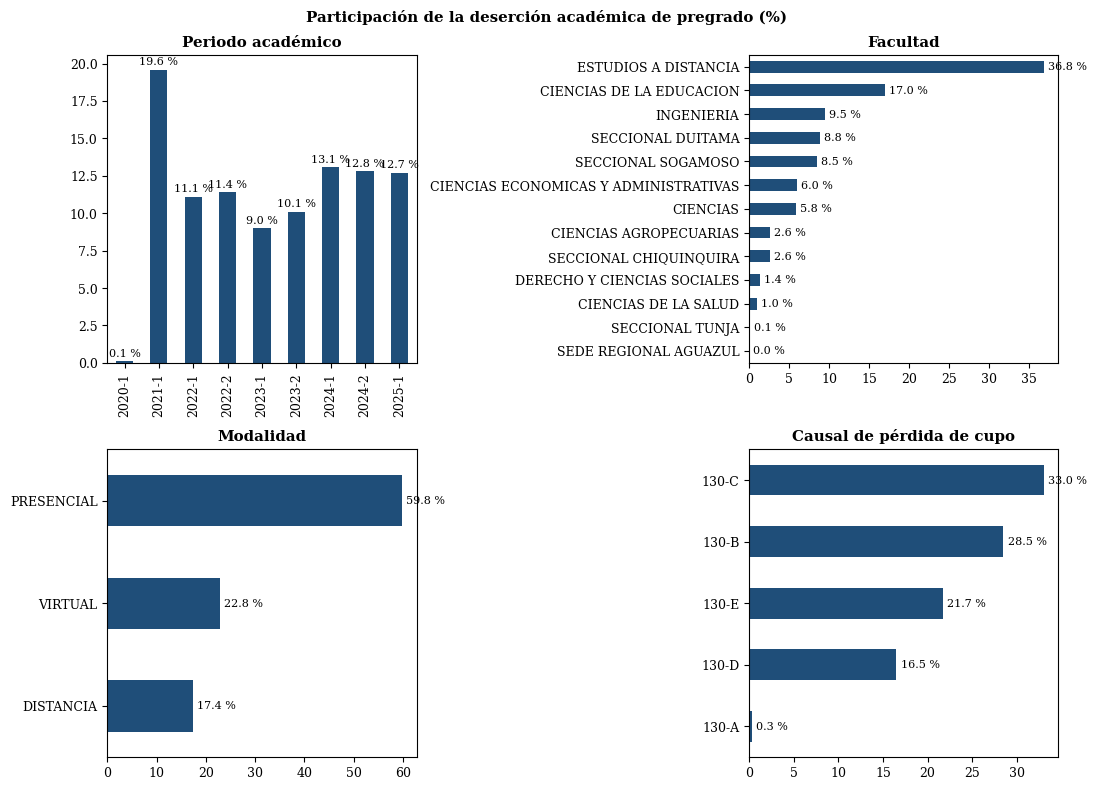

In [25]:
import matplotlib.pyplot as plt

AZUL = "#1F4E79"
plt.rcParams.update({"font.family": "serif", "font.size": 9})

def participacion(col):
    t = df_limpio[col].value_counts().to_frame("registros")
    t["%"] = (t["registros"] / len(df_limpio) * 100).round(1)
    return t

for col in ["nombre_facultad", "nombre_sede", "modalidad", "causal", "rango_edad", "genero", "estrato"]:
    print(f"\n=== {col} ===")
    print(participacion(col).head(8))

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
graficos = [("periodo_cod", "Periodo académico"), ("nombre_facultad", "Facultad"),
            ("modalidad", "Modalidad"), ("causal", "Causal de pérdida de cupo")]
for ax, (col, titulo) in zip(axes.flat, graficos):
    t = participacion(col)
    t = t.sort_index() if col == "periodo_cod" else t.sort_values("registros")
    t["%"].plot(kind="bar" if col == "periodo_cod" else "barh", ax=ax, color=AZUL)
    ax.set_title(titulo, fontweight="bold"); ax.set_xlabel(""); ax.set_ylabel("")
    for i, v in enumerate(t["%"]):
        ax.annotate(f"{v} %", (i, v) if col == "periodo_cod" else (v, i),
                    ha="center" if col == "periodo_cod" else "left", va="bottom" if col == "periodo_cod" else "center",
                    fontsize=8, xytext=(0, 2) if col == "periodo_cod" else (3, 0), textcoords="offset points")
fig.suptitle("Participación de la deserción académica de pregrado (%)", fontweight="bold")
plt.tight_layout()
plt.savefig("fig_eda_univariado.png", dpi=200, bbox_inches="tight")
plt.show()

#### Hallazgos del análisis univariado
- El periodo 2021-1 concentra el 19,6 % de los registros; desde 2024-1 la participación se mantiene cerca del 13 % por semestre. El periodo 2020-1 tiene solo 4 registros.
- La Facultad de Estudios a Distancia reúne el 36,8 % de los registros, seguida de Ciencias de la Educación (17,0 %).
- La sede Tunja concentra el 54,9 %, seguida de Sogamoso (13,8 %) y Duitama (13,1 %).
- Por modalidad, el 59,8 % es presencial, el 22,8 % virtual y el 17,4 % a distancia.
- Las causales 130-C (33,0 %) y 130-B (28,5 %) explican el 61,5 % de los casos.
- El 61,0 % son hombres, el 85,3 % pertenece a los estratos 1 y 2, y el rango de edad más frecuente es 21-25 años (42,2 %).

### 6.2 Análisis multivariado
Se cruzan dos variables mediante tablas de contingencia, con porcentajes por fila, para identificar si la distribución de la deserción académica cambia según la categoría de otra variable.

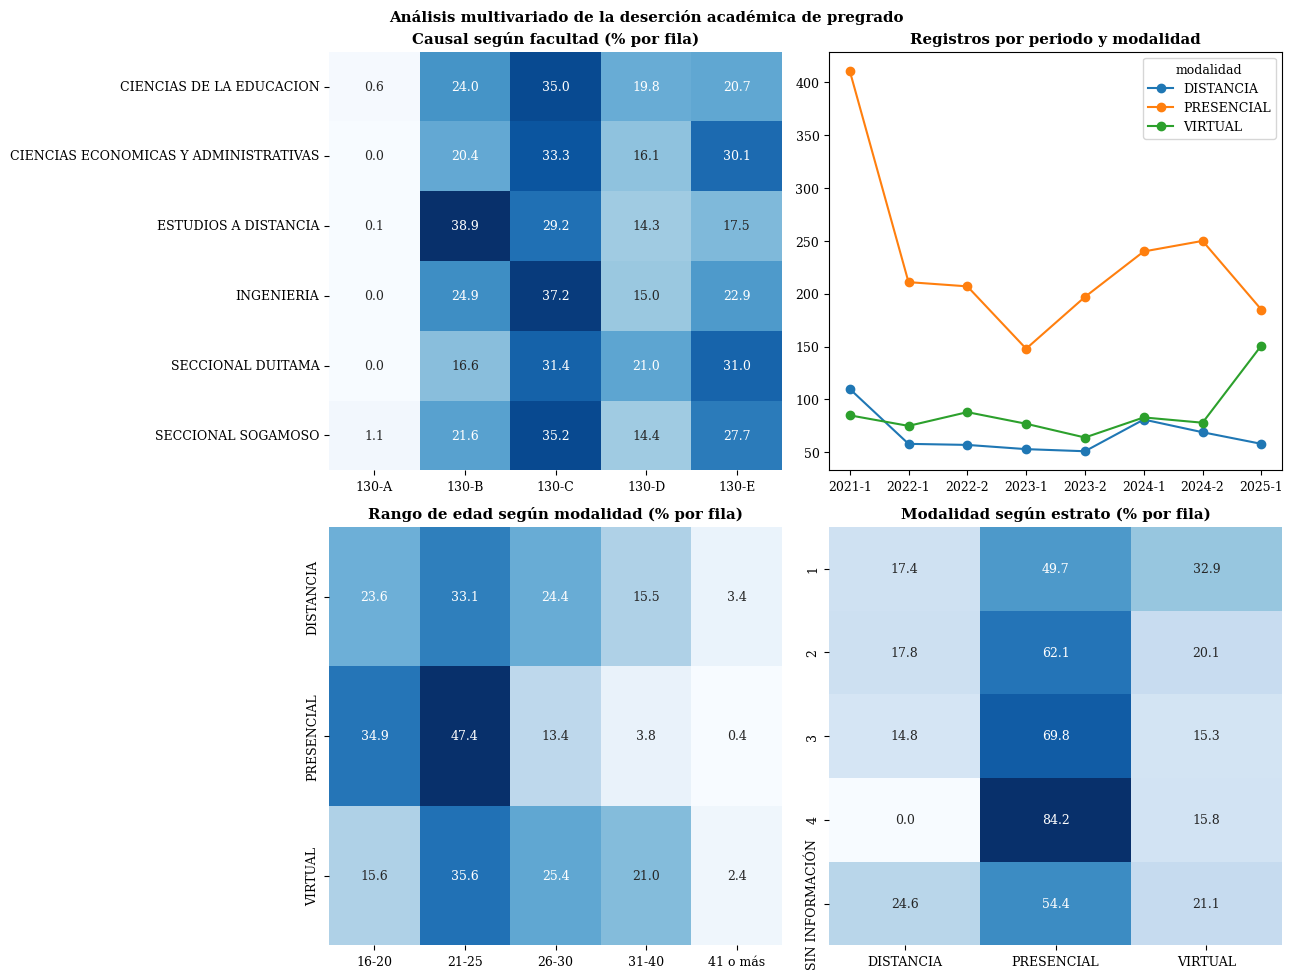

In [26]:
import seaborn as sns

def cruce(fila, columna, top=None):
    datos = df_limpio
    if top:
        datos = datos[datos[fila].isin(datos[fila].value_counts().index[:top])]
    return (pd.crosstab(datos[fila], datos[columna], normalize="index") * 100).round(1)

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

sns.heatmap(cruce("nombre_facultad", "causal", top=6), annot=True, fmt=".1f", cmap="Blues", cbar=False, ax=axes[0, 0])
axes[0, 0].set_title("Causal según facultad (% por fila)", fontweight="bold")

serie = pd.crosstab(df_limpio["periodo_cod"], df_limpio["modalidad"]).drop(index="2020-1", errors="ignore")
serie.plot(marker="o", ax=axes[0, 1])
axes[0, 1].set_title("Registros por periodo y modalidad", fontweight="bold")

sns.heatmap(cruce("modalidad", "rango_edad"), annot=True, fmt=".1f", cmap="Blues", cbar=False, ax=axes[1, 0])
axes[1, 0].set_title("Rango de edad según modalidad (% por fila)", fontweight="bold")

sns.heatmap(cruce("estrato", "modalidad"), annot=True, fmt=".1f", cmap="Blues", cbar=False, ax=axes[1, 1])
axes[1, 1].set_title("Modalidad según estrato (% por fila)", fontweight="bold")

for ax in axes.flat:
    ax.set_xlabel(""); ax.set_ylabel("")
fig.suptitle("Análisis multivariado de la deserción académica de pregrado", fontweight="bold")
plt.tight_layout()
plt.savefig("fig_eda_multivariado.png", dpi=200, bbox_inches="tight")
plt.show()

#### Hallazgos del análisis multivariado
- **Causal según facultad:** la causal 130-C predomina en la mayoría de las facultades (entre 31 % y 37 %), pero en la Facultad de Estudios a Distancia predomina la 130-B (38,9 %), y la 130-E tiene mayor peso en Ciencias Económicas y Administrativas (30,1 %) y en la Seccional Duitama (31,0 %).
- **Periodo y modalidad:** la modalidad presencial registra su valor más alto en 2021-1 y luego desciende; la modalidad virtual aumenta en 2025-1, su valor más alto en la serie.
- **Edad según modalidad:** en la modalidad presencial el 82,3 % tiene entre 16 y 25 años, mientras que en las modalidades virtual y a distancia la proporción de estudiantes de 31 años o más es mayor (23,4 % y 18,9 %).
- **Modalidad según estrato:** el estrato 1 presenta la mayor proporción en modalidad virtual (32,9 %); a mayor estrato, mayor proporción en modalidad presencial (69,8 % en estrato 3 y 84,2 % en estrato 4).
- Estas diferencias se contrastarán con pruebas chi-cuadrado en la etapa de rigor analítico.
